# 04- Implementación modelos de regresión supervisada

**Proyecto Final Machine Learning**  
Adriana Lorenzo Mingorance

En este notebook vamos a construir distintos modelos de regresión supervisada para predecir la variable: unidades_curriculares_2do_semestestre_califiacion (la media del estudiante en el 2º semestre) . 

Los modelos que vamos a implementar son:
1. Regresión Lineal
2. Ridge
3. Lasso
4. Random Forest Regressor
5. Gradient Boosting Regressor


In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score



## 1. Carga de datos

In [2]:
from sklearn.preprocessing import StandardScaler

X_train = pd.read_csv('../data/X_train_reg.csv')
X_test = pd.read_csv('../data/X_test_reg.csv')

#convertimos a float
X_train = X_train.astype(float)
X_test = X_test.astype(float)
print(X_train.dtypes.value_counts())

y_train = pd.read_csv('../data/y_train_reg.csv').squeeze()
y_test = pd.read_csv('../data/y_test_reg.csv').squeeze()

#reescalamos aquí directamente
scaler = StandardScaler()
#X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
#X_test_sc  = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

X_train_sc = pd.read_csv('../data/X_train_reg_scaled.csv')
X_test_sc = pd.read_csv('../data/X_test_reg_scaled.csv')

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Clases: {y_train.value_counts().to_dict()}")
print(f"Target train: media: {y_train.mean():.2f}, std: {y_train.std():.2f}")
print(f"Min: {y_train.min():.2f} | Max: {y_train.max():.2f}")
print(f"Porcentaje de ceros: {(y_train == 0).mean()*100:.1f}%")

float64    232
Name: count, dtype: int64
Train: (3539, 232) | Test: (885, 232)
Clases: {0.0: 697, 12.0: 134, 11.0: 126, 13.0: 121, 12.5: 73, 11.5: 70, 14.0: 65, 10.0: 56, 12.666666666666666: 52, 11.333333333333334: 51, 13.5: 50, 12.333333333333334: 45, 11.666666666666666: 44, 11.6: 39, 13.333333333333334: 38, 10.5: 38, 12.8: 37, 11.25: 37, 12.6: 36, 11.8: 36, 13.666666666666666: 35, 12.833333333333334: 35, 12.4: 34, 12.166666666666666: 33, 12.2: 32, 11.4: 30, 14.166666666666666: 28, 11.75: 27, 12.25: 26, 13.2: 26, 10.666666666666666: 22, 12.75: 22, 15.0: 21, 11.2: 21, 13.285714285714286: 19, 13.166666666666666: 19, 11.833333333333334: 19, 14.5: 18, 13.4: 18, 14.333333333333334: 17, 13.25: 17, 10.75: 16, 14.666666666666666: 15, 10.333333333333334: 15, 14.2: 14, 16.0: 14, 13.8: 13, 13.75: 13, 12.428571428571429: 13, 13.6: 13, 13.142857142857142: 12, 13.714285714285714: 12, 12.142857142857142: 12, 14.8: 12, 12.285714285714286: 11, 11.166666666666666: 11, 13.833333333333334: 11, 14.4285714

Hemos excluido todas las variables del segundo semestre para evitar data leakage, ya que contienen información directamente relacionada con la variable objetivo (nota_media_2sem).


## 2. Distribución del target

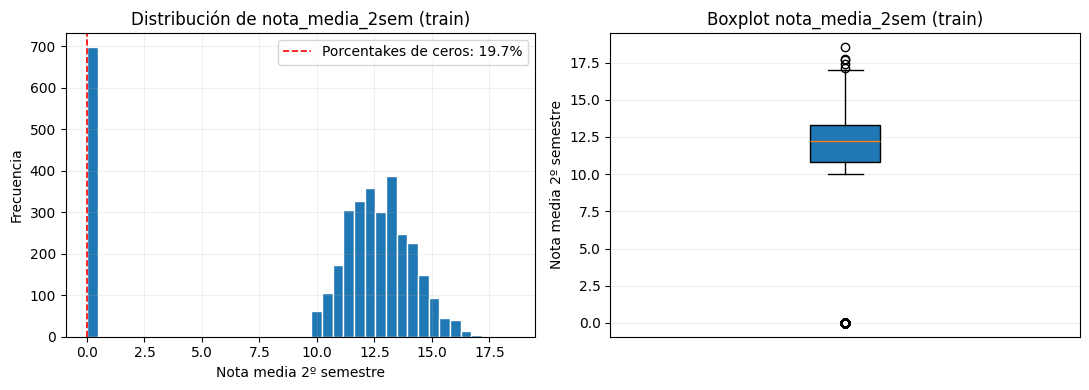

In [3]:
fig, axes = plt.subplots(1,2, figsize=(11, 4))

#histograma del target
axes[0].hist(y_train, bins=40, edgecolor='white')
axes[0].set_title('Distribución de nota_media_2sem (train)')
axes[0].set_xlabel('Nota media 2º semestre')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(alpha=0.2)

#porcentaje de ceros (estudiantes con 0 en todo)
pct_ceros = (y_train == 0).mean() * 100
axes[0].axvline(0, color = 'red', linestyle='--', linewidth=1.2, label = f'Porcentakes de ceros: {pct_ceros:.1f}%')
axes[0].legend()

#boxplot para ver dispersion y posibles outliers
axes[1].boxplot(y_train.dropna(), vert=True, patch_artist=True)
axes[1].set_title('Boxplot nota_media_2sem (train)')
axes[1].set_ylabel('Nota media 2º semestre')
axes[1].set_xticks([])
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig('../figuras/distribucion_target_reg.png')
plt.show()


Nuestra variable objetivo: nota_media_2sem presenta una distribución asimétrica y un porcentaje relevante de valores iguales a cero. Esto puede reflejar casos de abandono temprano o estudiantes no evaluados, lo cual nos añade un reto adicional en la modelizacion a tener en cuenta.

Además, la presencia de posibles outliers y la asimetría de la distribución sugieren que los modelos lineales pueden tener dificultsdes para capturar correctamente la relación entre variables.

## 3. Función auxiliar de evaluación de modelos

In [4]:
resultados_reg = {}

def evaluar_modelo_reg(nombre, modelo, X_tr, X_test, y_tr, y_test):
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_test)

    #usamos las metricas que hemos importdo de sklearn
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    #hacemos validacion cruzada con k= 5 folds, sobre train
    cv_r2 = cross_val_score(modelo, X_tr, y_tr, cv=5, scoring='r2')

    #guardamos los resultados
    resultados_reg[nombre] = {
        'RMSE': round(rmse, 4),
        'MAE': round(mae,4),
        'R2': round(r2, 4),
        'CV R2 (mean)': round(cv_r2.mean(), 4),
        'CV R2 (std)': round(cv_r2.std(), 4)
    }

    print('\n')
    print(f' {nombre}')
    print()
    print(f" RMSE: {rmse:.4f}")
    print(f" MAE: {mae:.4f}")
    print(f" R2: {r2:.4f}")
    print(f" CV R2: {cv_r2.mean():.4f} +/- {cv_r2.std():.4f}")

    return modelo, y_pred

## 4. Modelo 1: Regresión lineal

In [5]:
lr = LinearRegression()

lr_fit, lr_pred = evaluar_modelo_reg('Regresión Lineal', lr, X_train_sc, X_test_sc, y_train, y_test)




 Regresión Lineal

 RMSE: 4844615653595.3408
 MAE: 260612023082.6607
 R2: -866896264914325859205120.0000
 CV R2: -583849879479544726283091968.0000 +/- 491405670220798233891831808.0000


Con los valores que obtenemos, vemos que la Regresion Lineal no es viable en este dataset, debido a la multicolinealidad perfecta introducida por el One-Hot Encoding (al tener 232 features, muchas combinaciones lineales dependientes). Esto hace que los coeficientes exploten y el modelo sea inestable, obteniendo esos valores tan elevados


## 5. Modelo 2: Ridge

In [6]:
ridge = Ridge(alpha=1.0)
ridge_fit, ridge_pred = evaluar_modelo_reg(
    'Ridge', ridge,
    X_train_sc, X_test_sc, y_train, y_test
)



 Ridge

 RMSE: 2.6796
 MAE: 1.6148
 R2: 0.7348
 CV R2: 0.7357 +/- 0.0353


Al usar Ridge, la regularización penaliza coeficientes grandes y resuelve exactamente el problema anterior. 
Esto es además más correcto cuando se trabaja con espacios de alta dimensión

## 6. Mdelo 3: Lasso

In [7]:
lasso = Lasso(alpha=0.01,max_iter=10000)

lasso_fit, lasso_pred = evaluar_modelo_reg('Lasso', lasso, X_train_sc, X_test_sc, y_train, y_test)



 Lasso

 RMSE: 2.6632
 MAE: 1.5770
 R2: 0.7380
 CV R2: 0.7430 +/- 0.0359


## 7. Modelo 4: Random Forest Regressor

In [8]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)

rf_fit, rf_pred = evaluar_modelo_reg('Random Forest', rf, X_train, X_test, y_train, y_test)



 Random Forest

 RMSE: 2.7334
 MAE: 1.3974
 R2: 0.7240
 CV R2: 0.7680 +/- 0.0452


## 8. Modelo 5: Gradient Boosting Regressor

In [9]:
gb = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42)

gb_fit, gb_pred = evaluar_modelo_reg('Gradient Boosting', gb, X_train, X_test, y_train, y_test)



 Gradient Boosting

 RMSE: 2.6347
 MAE: 1.4419
 R2: 0.7436
 CV R2: 0.7657 +/- 0.0401


## 8. Comparativa de modelos

In [16]:
df_res_reg = pd.DataFrame(resultados_reg).T

print('COMPARATIVA DE MODELOS: ')
print(df_res_reg.to_string())

mejor_modelo = df_res_reg['R2'].idxmax()
print(f"\nMejor modelo: {mejor_modelo}. R2= {df_res_reg.loc[mejor_modelo, 'R2']}")

COMPARATIVA DE MODELOS: 
                           RMSE           MAE            R2  CV R2 (mean)   CV R2 (std)
Regresión Lineal   4.844616e+12  2.606120e+11 -8.668963e+23 -5.838499e+26  4.914057e+26
Ridge              2.679600e+00  1.614800e+00  7.348000e-01  7.357000e-01  3.530000e-02
Lasso              2.663200e+00  1.577000e+00  7.380000e-01  7.430000e-01  3.590000e-02
Random Forest      2.733400e+00  1.397400e+00  7.240000e-01  7.680000e-01  4.520000e-02
Gradient Boosting  2.634700e+00  1.441900e+00  7.436000e-01  7.657000e-01  4.010000e-02

Mejor modelo: Gradient Boosting. R2= 0.7436


## 9. Gráfica General comparativa pred vs real

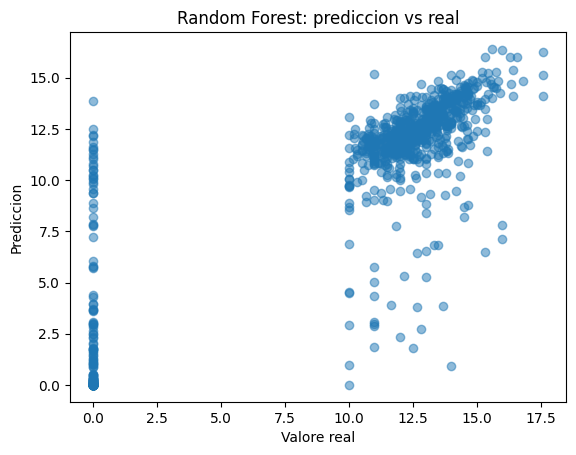

In [11]:
plt.scatter(y_test, rf_pred, alpha=0.5)
plt.xlabel('Valore real')
plt.ylabel('Prediccion')
plt.title('Random Forest: prediccion vs real')
plt.savefig('../figuras/prediccion_vs_real_reg.png')
plt.show()

Esta gráfica muestra una buena relación entre los valroes reales y las prediccioens, observándose una tendencia cercana a la diagonal, lo que indica un buen ajuste del modelo.
Sin embargo, hay una mayor dispersión en algunos punto (en valores bajos y extremos), lo que nos puede indicar la dificultad del modelo para predecir ciertos perfiels de estudiantes.

Destacamos la presencia de muchos casos con valor real cercano a 0, el modelo no sabe predicir los casos con nota 0; introduciéndose ruido y afectando a su precisión.

En general, el modelo captura correctamente la tendencia global, aunque presenta errores en observaciones atípicas

## 9. Gráfica: predicciones vs valores reales

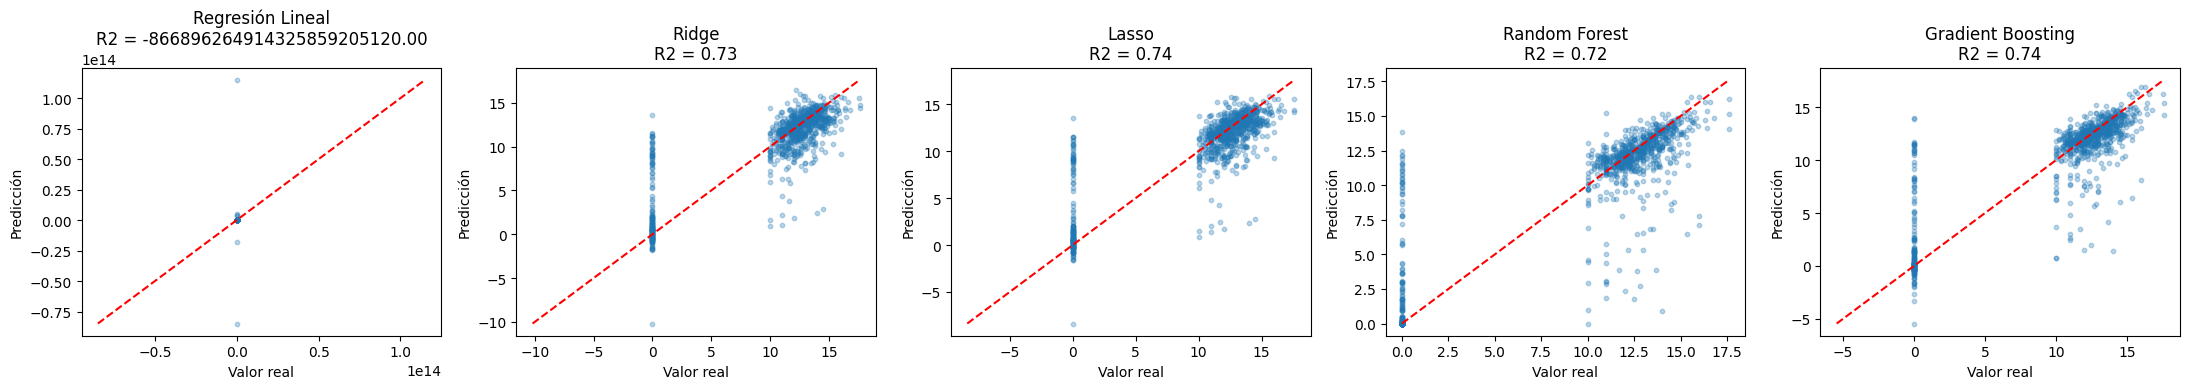

In [17]:
modelos_pred = [('Regresión Lineal', lr_pred), ('Ridge', ridge_pred), ('Lasso', lasso_pred), ('Random Forest', rf_pred), ('Gradient Boosting', gb_pred)]

fig, axes = plt.subplots(1,5, figsize=(22,4))

for ax, (nombre, y_pred) in zip(axes, modelos_pred):

    ax.scatter(y_test, y_pred, alpha=0.3, s=10)

    #linea ideal (y=x)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--')

    #R2
    r2 = resultados_reg[nombre]['R2']

    ax.set_title(f'{nombre}\nR2 = {r2:.2f}')
    ax.set_xlabel('Valor real')
    ax.set_ylabel('Predicción')

plt.tight_layout()
plt.show()

La comparación de predicciones frente a valores reales muestra diferencias claras entre modelos.
La regresión lineal, como hemos deducido, muestra un comportamiento inestable, con predicciones fuera de escala y un R2 fuertemente negativo, lo que indica un mal ajuste del modelo. Este comportamiento puede explicarse por la alta dimensionalidad y la multicolinealdiad de las variables.

Sin embargo, al introducir regularización con Ridge o Lasso, el modelo mejora bastante (R2 = 0.73/0.74 aprox.), mostrando una relación más clara con la diagonal ideal.

Los modelos basados en árboles (RF y GB) presentan también buen ajsute, mostrando incluso cierta mejores respecto a los modelos lineales.

En todos vemos dificultad común para predecir los casos con nota igual a 0, como hemos mencionado en la gráfica anterior

## 10. Importancia de variables

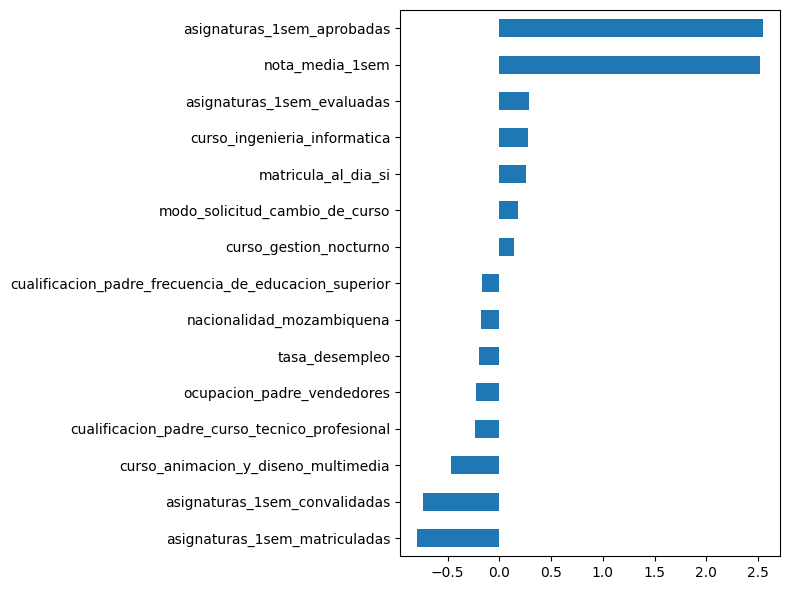

In [13]:
#Importancia de variables con Lasso: usamos coeficientes
coeficientes= pd.Series(lasso_fit.coef_,
                         index=X_train_sc.columns)

coef_no_cero = coeficientes[coeficientes !=0]

top15 = coef_no_cero.reindex(coef_no_cero.abs().sort_values(ascending=False).head(15).index)


plt.figure(figsize=(8, 6))
top15.sort_values().plot(kind='barh')
ax.set_title('Top 15 variables más importantes (Random Forest)')
ax.set_xlabel('Coeficiente')
plt.tight_layout()
#plt.savefig('../figuras/importancia_variables_clf.png')
plt.show()

Para analizar la relevancia de las variables, hemos utilizado Lasso, ya que este modelo realiza, tal y como hemos estudiado, la selección automática al llevar algunos coeficientes exactamente a cero.

Las variables con coef!=0, son als que el modelo considera más útiles para predecir la nota del segundo semestre. Además, el signo del coeficiente permite interpretar si su efecto es + ó - sobre la predicción

## 11. Análisis de residuos

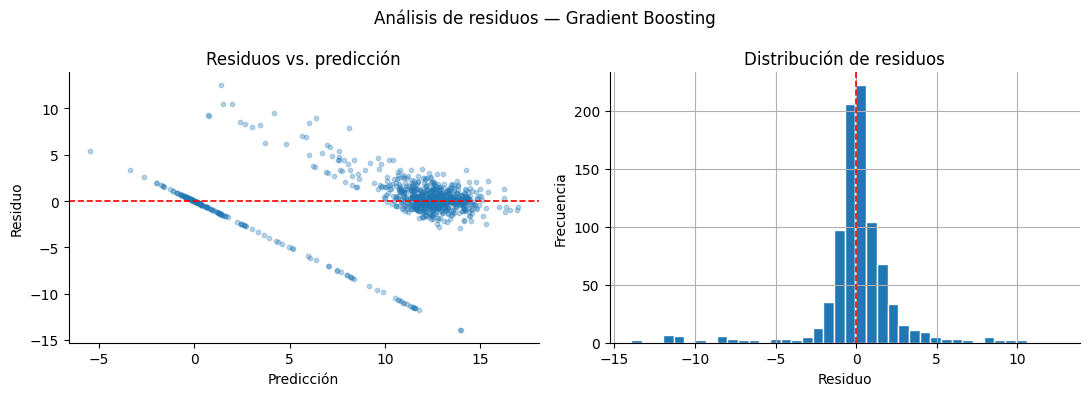

In [14]:
# Elegimos el mejor modelo para analizar residuos
preds_mejor = {
    'Regresión Lineal': lr_pred,
    'Ridge': ridge_pred,
    'Random Forest': rf_pred,
    'Gradient Boosting': gb_pred
}[mejor_modelo]

residuos = y_test.values - preds_mejor

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

#residuos vs predicción
axes[0].scatter(preds_mejor, residuos, alpha=0.3, s=10)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2)
axes[0].set_title('Residuos vs. predicción')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Residuo')
sns.despine(ax=axes[0])

# Histograma de residuos
axes[1].hist(residuos, bins=40, edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.2)
axes[1].set_title('Distribución de residuos')
axes[1].set_xlabel('Residuo')
axes[1].set_ylabel('Frecuencia')
sns.despine(ax=axes[1])

fig.suptitle(f'Análisis de residuos — {mejor_modelo}', fontsize=12)
plt.tight_layout()
plt.grid()
plt.show()


En el análisis de residuos vemos cómo se concentran alrededor de cero, lo que indica que el modelo no presenta un sesgo sistemático importante, y en general, realia predicciones equilibradas.
Sin embargo, observamos cierta estructura en los residuos bastante simétrica (con algún valor atípico) lo que indica errores puntuales en ciertos casos.

En conjunto, el modelo presenta un buen ajuste global, aunque hay alguna limitación en la predicción de observaciones más complejas o menos representadas

## .. Resumen para el informe

In [15]:
print("Resumen para el informe: TAREA 2: REGRESIÓN")

print("\nTabla comparativa: ")
print(df_res_reg[['RMSE', 'MAE', 'R2']].to_string())

print(f"\nMejor modelo: {mejor_modelo}")
print(f" RMSE: {df_res_reg.loc[mejor_modelo, 'RMSE']}")
print(f" MAE: {df_res_reg.loc[mejor_modelo, 'MAE']}")
print(f" R2: {df_res_reg.loc[mejor_modelo, 'R2']}")


Resumen para el informe: TAREA 2: REGRESIÓN

Tabla comparativa: 
                           RMSE           MAE            R2
Regresión Lineal   4.844616e+12  2.606120e+11 -8.668963e+23
Ridge              2.679600e+00  1.614800e+00  7.348000e-01
Lasso              2.663200e+00  1.577000e+00  7.380000e-01
Random Forest      2.733400e+00  1.397400e+00  7.240000e-01
Gradient Boosting  2.634700e+00  1.441900e+00  7.436000e-01

Mejor modelo: Gradient Boosting
 RMSE: 2.6347
 MAE: 1.4419
 R2: 0.7436


Los resultados muestran que la regresión no es adecuada para este problema si seguimos el one-hot encoding con dummys porque tenemos muchas más variables (232); lo que indica que la relacion entre todas esas variables y la nota del segundo semestre no es puramente lineal.

Los modelos más robustos (Ridge, Random Forest, Gradient Boosting y Lasso), presentan un rendimiento similar, con R2 alrededor de 0.73-0.74, lo qeu indica una buena capacidad predictiva.

Boosting obtiene el mejor resultando, sugiriendo que modelar relaciones no lineales aporta una ligera mejora.

Para la interpretación, Lasso permite identificar automáticamente las variables más relevantes, siendo muy útil en contexto de alta dimensionalidad como es el caso.